In [ ]:
import numpy as np 
import tensorflow_hub as hub

c:\Users\Yernar\Desktop\NLP\etc1\venv2\Lib\site-packages\tensorflow_hub\__init__.py:61: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import parse_version


In [2]:
embed = hub.load("wiki_words")

In [12]:
simple_sentences = [
    "excellent",
    "great",
    "terrible",
    "awful"
]
# 1 for positive, 0 for negative
simple_labels = [1, 1, 0, 0] 

# 2. Get embeddings using our previously defined function
def get_word2vec_enc(texts):
    """
    Get the 250-dimensional vector value for each word in the sentence.
    """
    encoded_texts = []
    for text in texts:
        tokens = text.split(" ")
        word2vec_embedding = embed(tokens) # embed(["excellent"])
        # print(word2vec_embedding) # Координаты слова в 250D пространстве
        # print(word2vec_embedding.shape) # (1,250)
        encoded_texts.append(word2vec_embedding)
    return encoded_texts

simple_encoded = get_word2vec_enc(simple_sentences)

# 3. Calculate a single "sentence vector" for each by taking the mean of its words
sentence_embeddings = np.array([np.mean(enc, axis=0) for enc in simple_encoded])
print(f"Shape of our simple sentence embeddings: {sentence_embeddings.shape}")

Shape of our simple sentence embeddings: (4, 250)


In [6]:
simple_encoded

[<tf.Tensor: shape=(1, 250), dtype=float32, numpy=
 array([[ 6.06750622e-02,  4.05055359e-02,  1.29511626e-02,
         -6.39005899e-02, -8.59993547e-02,  4.40602750e-02,
         -5.20495698e-02, -1.06183998e-01, -4.87041436e-02,
          7.83495903e-02,  5.27166296e-03,  2.07580522e-01,
          2.32040305e-02,  9.02940333e-02,  7.17873033e-03,
          3.37934727e-03, -3.62943150e-02, -6.83614314e-02,
         -6.70830905e-02, -3.97101790e-02,  1.20328754e-01,
          1.25417978e-01,  5.11294007e-02, -7.04192743e-02,
          8.55967551e-02, -3.49943675e-02, -6.07493408e-02,
          7.04115406e-02, -7.24723749e-03, -1.24989133e-02,
          1.43001705e-01, -6.85621426e-02, -2.22887099e-02,
          2.60360632e-03, -8.28821138e-02,  5.02248257e-02,
         -1.67382197e-04,  7.20441788e-02, -1.76316425e-02,
         -3.08036190e-02,  6.62451237e-02,  4.97135930e-02,
         -5.98616712e-02, -3.62015180e-02,  1.42053604e-01,
          9.16028395e-02, -8.18932354e-02, -4.893

In [4]:
sentence_embeddings

array([[ 6.06750622e-02,  4.05055359e-02,  1.29511626e-02,
        -6.39005899e-02, -8.59993547e-02,  4.40602750e-02,
        -5.20495698e-02, -1.06183998e-01, -4.87041436e-02,
         7.83495903e-02,  5.27166296e-03,  2.07580522e-01,
         2.32040305e-02,  9.02940333e-02,  7.17873033e-03,
         3.37934727e-03, -3.62943150e-02, -6.83614314e-02,
        -6.70830905e-02, -3.97101790e-02,  1.20328754e-01,
         1.25417978e-01,  5.11294007e-02, -7.04192743e-02,
         8.55967551e-02, -3.49943675e-02, -6.07493408e-02,
         7.04115406e-02, -7.24723749e-03, -1.24989133e-02,
         1.43001705e-01, -6.85621426e-02, -2.22887099e-02,
         2.60360632e-03, -8.28821138e-02,  5.02248257e-02,
        -1.67382197e-04,  7.20441788e-02, -1.76316425e-02,
        -3.08036190e-02,  6.62451237e-02,  4.97135930e-02,
        -5.98616712e-02, -3.62015180e-02,  1.42053604e-01,
         9.16028395e-02, -8.18932354e-02, -4.89382558e-02,
         5.43272085e-02,  3.24413180e-02, -1.44002242e-0

In [11]:
from sklearn.decomposition import PCA

# Reduce the 250-dimensional vectors down to 2 dimensions
pca = PCA(n_components=2)
embeddings_2d = pca.fit_transform(sentence_embeddings)

print(f"Shape after PCA reduction: {embeddings_2d.shape}")

Shape after PCA reduction: (4, 2)


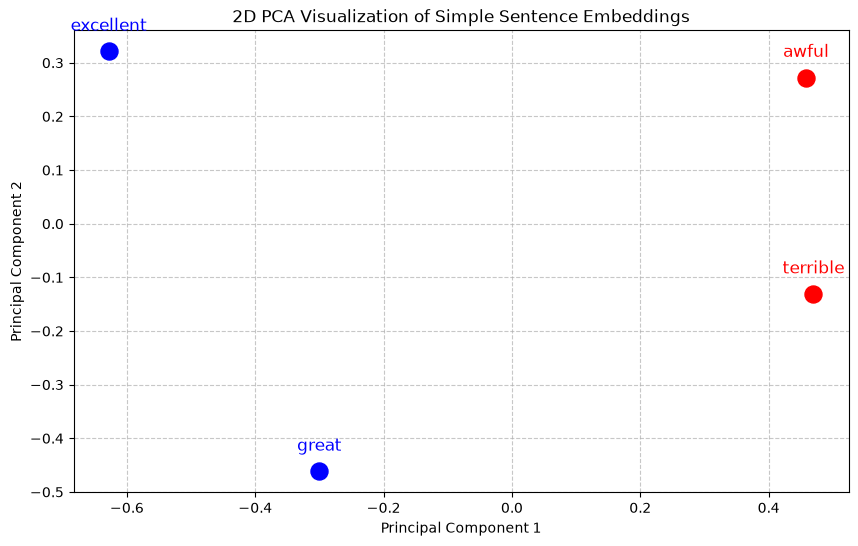

In [13]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

# Plot each simple sentence
for i, label in enumerate(simple_labels):
    color = 'blue' if label == 1 else 'red'
    plt.scatter(embeddings_2d[i, 0], embeddings_2d[i, 1], color=color, s=150)
    plt.annotate(simple_sentences[i], (embeddings_2d[i, 0], embeddings_2d[i, 1]), 
                 textcoords="offset points", xytext=(0,15), ha='center', color=color, fontsize=12)

plt.title("2D PCA Visualization of Simple Sentence Embeddings")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.grid(True, linestyle='--', alpha=0.7)
plt.show()

In [14]:
def calc_cosine_similarity(A, B):
    """Calculates the cosine similarity between two vectors."""
    return np.dot(A, B) / (np.linalg.norm(A) * np.linalg.norm(B))

# 1. Get embeddings for our simple words
# Calling .numpy() converts the TensorFlow tensor back to a standard NumPy array
excellent_vector = embed(["excellent"])[0].numpy()
great_vector = embed(["great"])[0].numpy()
terrible_vector = embed(["terrible"])[0].numpy()

# 2. Calculate the Cosine Similarities
sim_excellent_great = calc_cosine_similarity(excellent_vector, great_vector)
sim_excellent_terrible = calc_cosine_similarity(excellent_vector, terrible_vector)

print(f"Similarity between 'excellent' and 'great': {sim_excellent_great:.4f}")
print(f"Similarity between 'excellent' and 'terrible': {sim_excellent_terrible:.4f}")

Similarity between 'excellent' and 'great': 0.6199
Similarity between 'excellent' and 'terrible': 0.2855
